# **Inventory Management**

**Load the required Python libraries**

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

**Interpretation** :

“I imported Pandas and NumPy for data handling and numerical operations. I imported Matplotlib and Seaborn to create visualizations for exploratory data analysis.”

**Load Excel dataset**

In [4]:
df = pd.read_excel('/content/stock_risk_prediction_dataset (1).xlsx')

print("Dataset loaded successfully")
print(df.head())

Dataset loaded successfully
   current_stock  avg_daily_demand  lead_time_days  reorder_point  \
0            549             45.76            5.64         342.83   
1            486             45.47            6.39         348.37   
2            564             32.04            5.81         353.21   
3            652             46.70            7.22         397.34   
4            476             57.33            9.39         312.64   

   sales_last_30_days  stock_turnover_ratio  forecast_error    season  \
0             1604.49                  4.17           -9.90      peak   
1             1585.00                  4.01           -5.27      peak   
2             1219.04                  3.57           -2.94  off-peak   
3             1673.88                  4.00            0.75  off-peak   
4             1052.98                  4.49            5.12      peak   

   item_category supplier_reliability stock_status  
0      essential                  low    overstock  
1  non-essen

**Interpretation:**

“I loaded the Stock Risk Prediction Dataset into a DataFrame. I displayed the first five rows to understand the structure of the inventory data.”

**Check the number of rows and columns**

In [5]:
print("Dataset shape:", df.shape)
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])

Dataset shape: (5000, 11)
Number of rows: 5000
Number of columns: 11


**Interpretation:**

“Our dataset contains 5,000 records and 11 columns. Ten columns are input features, and one column, stock_status, is the target variable.”

Display column names

In [6]:
print(df.columns.tolist())

['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error', 'season', 'item_category', 'supplier_reliability', 'stock_status']


**Interpretation:**

“This step identifies all available features and helps us verify that the dataset contains the required columns for inventory risk prediction.”

**Check data types and non-null values**

In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 5000 entries, 0 to 4999
Data columns (total 11 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   current_stock         5000 non-null   int64  
 1   avg_daily_demand      5000 non-null   float64
 2   lead_time_days        5000 non-null   float64
 3   reorder_point         5000 non-null   float64
 4   sales_last_30_days    5000 non-null   float64
 5   stock_turnover_ratio  5000 non-null   float64
 6   forecast_error        5000 non-null   float64
 7   season                5000 non-null   object 
 8   item_category         5000 non-null   object 
 9   supplier_reliability  5000 non-null   object 
 10  stock_status          5000 non-null   object 
dtypes: float64(6), int64(1), object(4)
memory usage: 429.8+ KB


**Interpretation:**

“I checked the data types of each column. Numerical features describe stock and demand measurements, while categorical features describe business conditions. This helps us plan the preprocessing required before model building.”

***EDA part***

**Check missing values**

In [8]:
print("Total missing values:", df.isnull().sum().sum())

Total missing values: 0


**Interpretation:**

“I checked every column for missing values. No missing values were found, so missing-value imputation is not required for the current dataset.”

**Check duplicate records**

In [9]:
print("Number of duplicate rows:", df.duplicated().sum())

Number of duplicate rows: 0


**Interpretation:**

“I checked for duplicate records. No duplicate rows were found, so duplicate removal is not required.”

**Generate descriptive statistics**

In [10]:
df.describe().round(2)

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error
count,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00,5000.00
mean,500.07,49.90,7.02,350.83,1494.49,3.99,-0.05
std,99.65,10.10,2.00,50.17,295.01,1.00,5.13
min,175.00,10.78,0.25,157.18,403.47,0.55,-22.33
25%,434.00,43.13,5.68,316.76,1289.47,3.30,-3.54
50%,501.00,49.82,7.02,350.96,1497.59,4.00,-0.12
75%,566.00,56.77,8.35,385.33,1695.18,4.68,3.44
max,892.00,85.29,13.86,573.95,2583.41,7.69,18.64


**Interpretation:**

“Descriptive statistics summarize the central values and ranges of numerical features. For example, average daily demand is approximately 50 units, and the average supplier lead time is about seven days. These measurements help us understand the scale and variability of inventory data.”
These are dataset-wide statistics, not the values for any individual product.

**Analyze the target column**

This is one of the most important EDA steps because our model must predict stock_status.

In [11]:
print(df['stock_status'].value_counts())

print("\nPercentage distribution:")
print(
    (df['stock_status'].value_counts(normalize=True) * 100).round(2)
)

stock_status
overstock    4543
stockout      457
Name: count, dtype: int64

Percentage distribution:
stock_status
overstock    90.86
stockout      9.14
Name: proportion, dtype: float64


**Create a chart:**

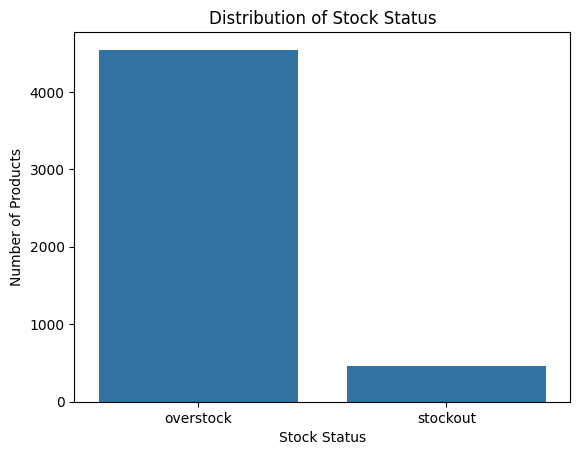

In [12]:
sns.countplot(data=df, x='stock_status')
plt.title('Distribution of Stock Status')
plt.xlabel('Stock Status')
plt.ylabel('Number of Products')
plt.show()

**Interpretation for presentation:**

“The target variable contains two classes: overstock and stockout. Overstock represents approximately 90.86% of the records, while stockout represents 9.14%. This is a significant class imbalance, so during model evaluation we must examine precision, recall, F1-score and the confusion matrix, not accuracy alone.”

**Analyze categorical features**

In [13]:
categorical_columns = [
    'season',
    'item_category',
    'supplier_reliability'
]

for col in categorical_columns:
    print(f"\nDistribution of {col}:")
    print(df[col].value_counts())


Distribution of season:
season
off-peak    2508
peak        2492
Name: count, dtype: int64

Distribution of item_category:
item_category
essential        2505
non-essential    2495
Name: count, dtype: int64

Distribution of supplier_reliability:
supplier_reliability
low     2514
high    2486
Name: count, dtype: int64


**Create visualizations:**

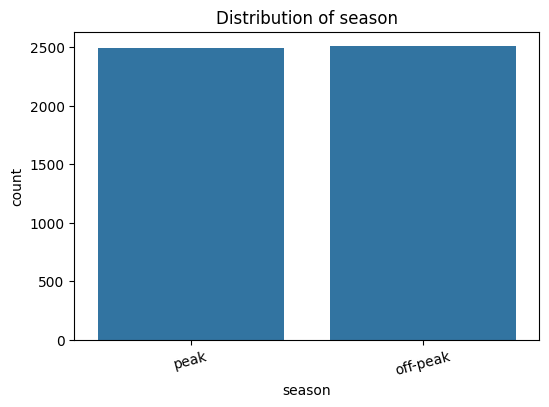

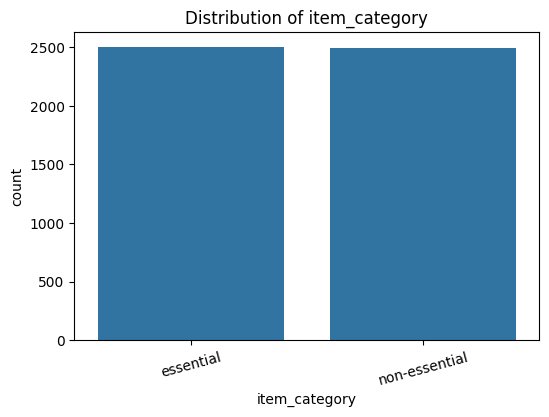

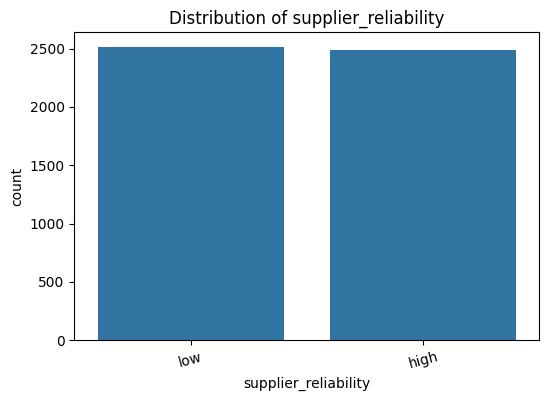

In [14]:
for col in categorical_columns:
    plt.figure(figsize=(6, 4))
    sns.countplot(data=df, x=col)
    plt.title(f'Distribution of {col}')
    plt.xticks(rotation=15)
    plt.show()

**Interpretation:**

“I analyzed the categorical features to understand the distribution of peak and off-peak seasons, essential and non-essential products, and supplier reliability. These features may help the model identify inventory risk patterns.”

**Analyze numerical feature distributions**

Histograms help us understand how numerical values are distributed.

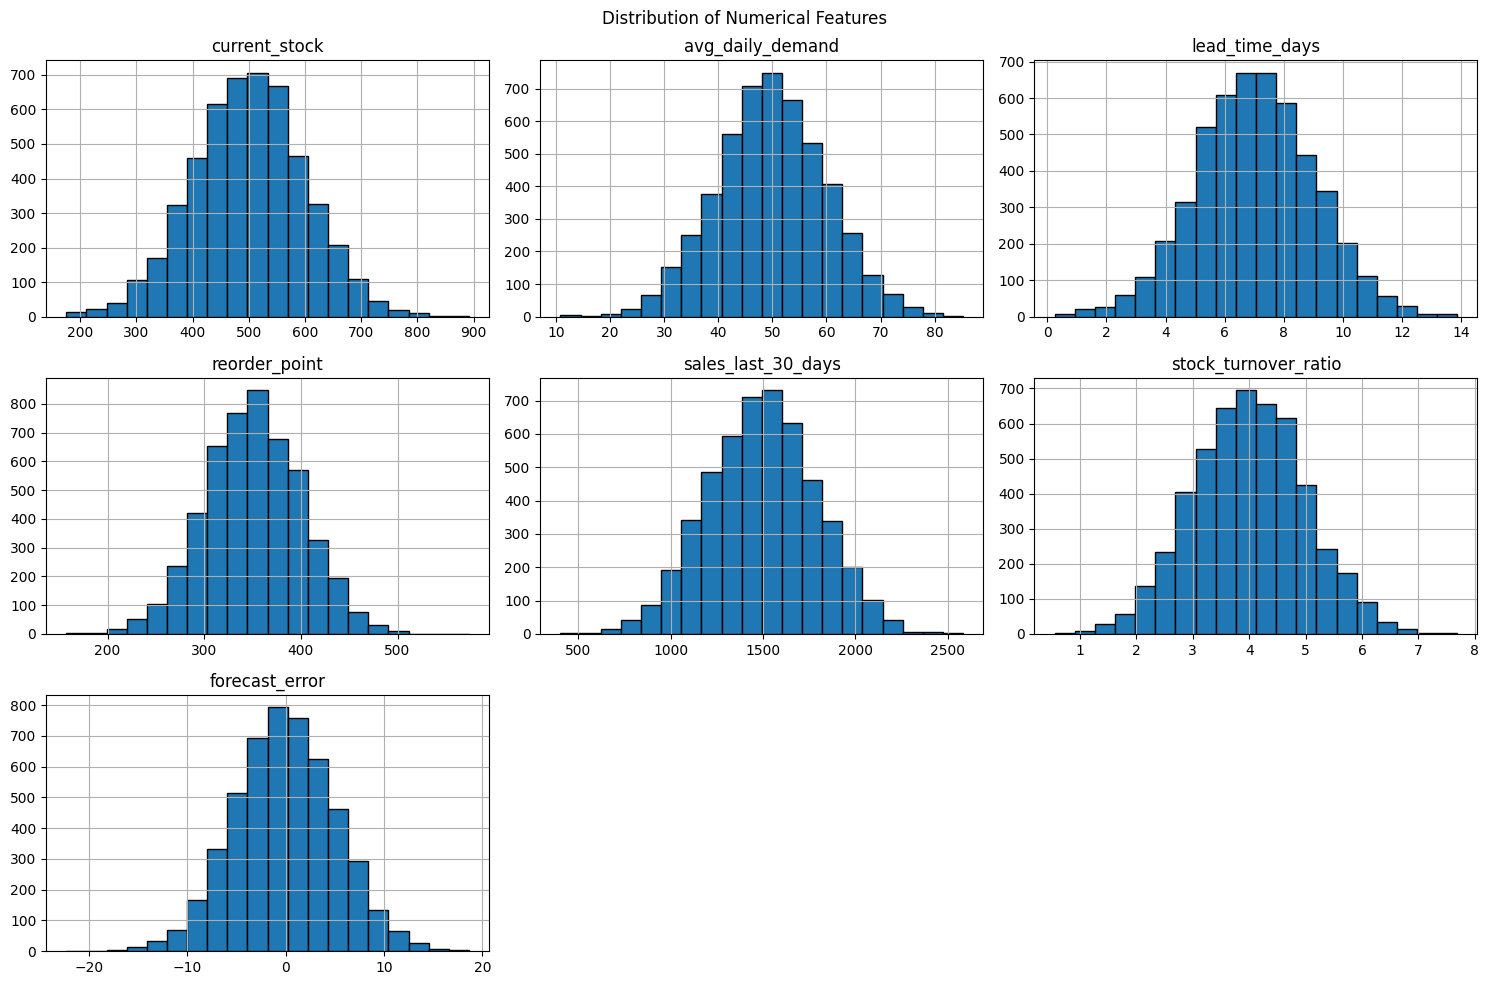

In [15]:
numerical_columns = df.select_dtypes(
    include=['int64', 'float64']
).columns

df[numerical_columns].hist(
    figsize=(15, 10),
    bins=20,
    edgecolor='black'
)

plt.suptitle('Distribution of Numerical Features')
plt.tight_layout()
plt.show()

**Interpretation:**

“I used histograms to inspect the distributions of stock, demand, lead time, sales and other numerical variables. This helps identify skewness, unusual values and patterns that may influence model performance.”

**Check for outliers using boxplots**

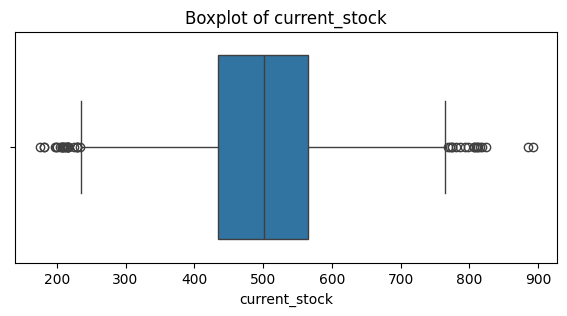

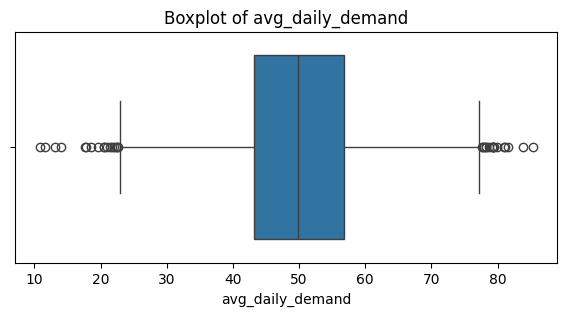

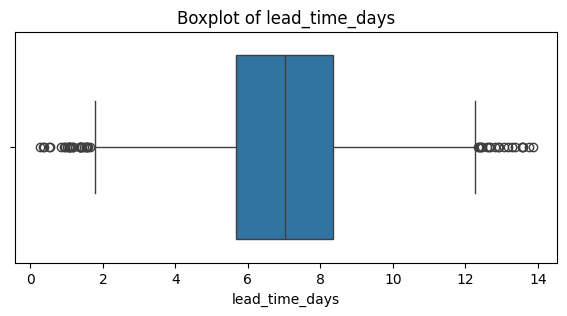

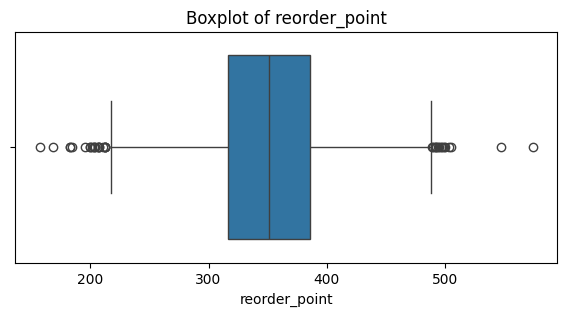

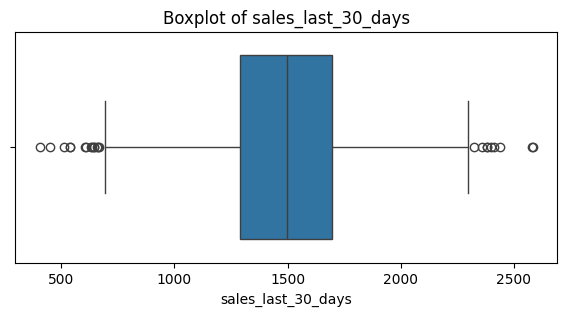

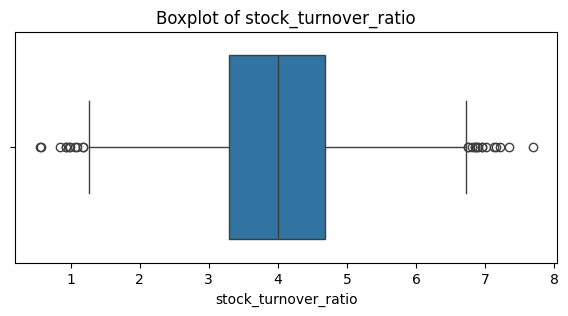

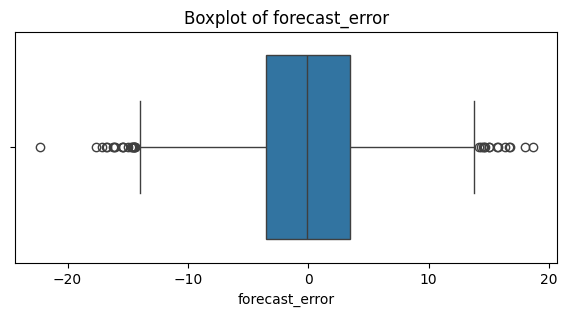

In [16]:
for col in numerical_columns:
    plt.figure(figsize=(7, 3))
    sns.boxplot(x=df[col])
    plt.title(f'Boxplot of {col}')
    plt.show()

**Interpretation:**

“Boxplots help identify potential outliers in numerical features. An unusual value is not automatically an error; it must be checked against the business context before deciding whether to retain or treat it.”

**Study relationships between numerical features**

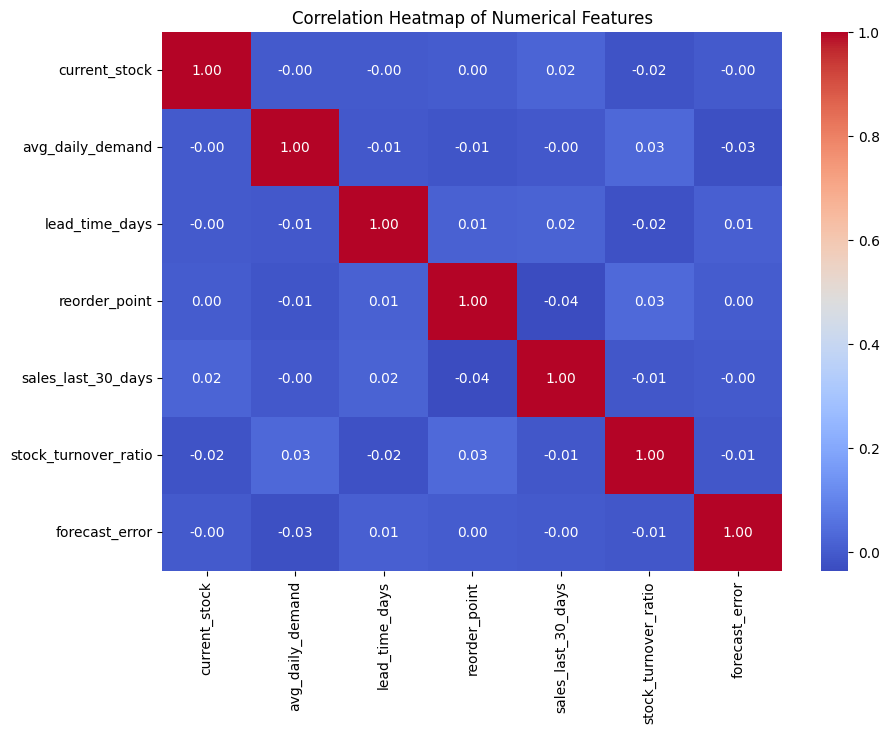

In [17]:
plt.figure(figsize=(10, 7))

correlation_matrix = df[numerical_columns].corr()

sns.heatmap(
    correlation_matrix,
    annot=True,
    cmap='coolwarm',
    fmt='.2f'
)

plt.title('Correlation Heatmap of Numerical Features')
plt.show()

Interpretation:
**bold text**
“The correlation heatmap shows the strength and direction of relationships between numerical features. It helps identify potentially related variables, but correlation alone does not prove causation or determine which features are most useful for prediction.”

**Compare features with stock status**


For example, compare the average daily demand for each stock-risk class.

In [18]:
print(
    df.groupby('stock_status')[
        ['current_stock', 'avg_daily_demand',
         'lead_time_days', 'reorder_point',
         'sales_last_30_days', 'stock_turnover_ratio',
         'forecast_error']
    ].mean().round(2)
)

              current_stock  avg_daily_demand  lead_time_days  reorder_point  \
stock_status                                                                   
overstock            516.32             49.89            7.03         346.65   
stockout             338.51             50.01            6.96         392.34   

              sales_last_30_days  stock_turnover_ratio  forecast_error  
stock_status                                                            
overstock                1495.41                  3.99           -0.04  
stockout                 1485.37                  4.07           -0.25  


**Visualize the comparison:**

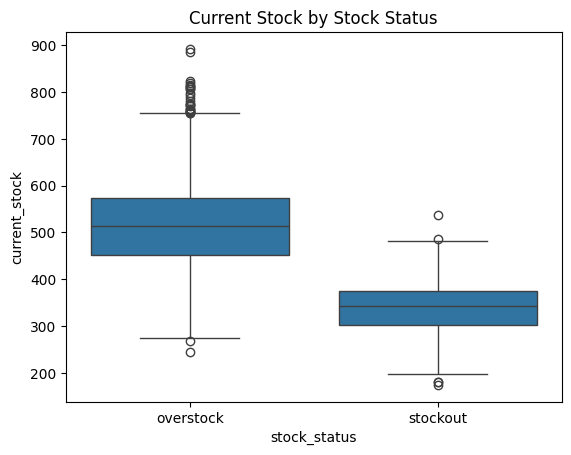

In [19]:
sns.boxplot(
    data=df,
    x='stock_status',
    y='current_stock'
)

plt.title('Current Stock by Stock Status')
plt.show()

**Interpretation:**

“This analysis compares inventory-related measurements across stockout and overstock records. It helps us investigate which features may distinguish the two risk classes. We will use the actual results rather than assume that any feature causes stockout or overstock.”

**Create an EDA summary table**

In [20]:
eda_summary = pd.DataFrame({
    'Check': [
        'Number of rows',
        'Number of columns',
        'Missing values',
        'Duplicate rows',
        'Target classes',
        'Majority class',
        'Minority class'
    ],
    'Result': [
        df.shape[0],
        df.shape[1],
        df.isnull().sum().sum(),
        df.duplicated().sum(),
        df['stock_status'].nunique(),
        df['stock_status'].value_counts().idxmax(),
        df['stock_status'].value_counts().idxmin()
    ]
})

print(eda_summary)

               Check     Result
0     Number of rows       5000
1  Number of columns         11
2     Missing values          0
3     Duplicate rows          0
4     Target classes          2
5     Majority class  overstock
6     Minority class   stockout


This table summarizes the main dataset-quality checks and the class distribution for our report.

**Exploratory Data Analysis(EDA) – Conclusion**

The Stock Risk Prediction Dataset contains 5,000 records and 11 columns, including 10 input features and one target variable, stock_status. The dataset has no missing values or duplicate rows. The numerical and categorical features were analyzed using descriptive statistics, histograms, boxplots, count plots and a correlation heatmap.

The target variable is imbalanced: 90.86% of records are classified as overstock and 9.14% as stockout. Therefore, model evaluation must focus on class-wise precision, recall, F1-score and the confusion matrix in addition to accuracy.

The next phase is data preprocessing, followed by training and evaluating classification models to predict inventory stock risk.

**Model building — import libraries**

In [21]:
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer

from sklearn.linear_model import LogisticRegression
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import (
    accuracy_score, precision_score, recall_score,
    f1_score, classification_report,
    ConfusionMatrixDisplay
)

import matplotlib.pyplot as plt
import pandas as pd
import joblib

print("Libraries imported successfully")

Libraries imported successfully


**Interpretation:**

 “I imported the required libraries for data splitting, preprocessing, training three classification models, evaluating their performance, and saving the selected model.”

**Separate input features and target**

In [22]:
X = df.drop(columns=['stock_status'])
y = df['stock_status']

print("Input shape:", X.shape)
print("Target shape:", y.shape)
print(y.value_counts())

Input shape: (5000, 10)
Target shape: (5000,)
stock_status
overstock    4543
stockout      457
Name: count, dtype: int64


**Interpretation:**

 “I selected the ten input features and the target column, stock_status, which identifies stockout or overstock.”

**Split training and testing data**

In [23]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (4000, 10)
X_test: (1000, 10)
y_train: (4000,)
y_test: (1000,)


**Interpretation:**

“I used 80% of the data for training and 20% for testing. Stratification helps preserve the target class proportions in both sets.”

**Prepare the features**

In [24]:
num_cols = X_train.select_dtypes(
    include='number'
).columns.tolist()

cat_cols = X_train.select_dtypes(
    exclude='number'
).columns.tolist()

print("Numerical columns:", num_cols)
print("Categorical columns:", cat_cols)

Numerical columns: ['current_stock', 'avg_daily_demand', 'lead_time_days', 'reorder_point', 'sales_last_30_days', 'stock_turnover_ratio', 'forecast_error']
Categorical columns: ['season', 'item_category', 'supplier_reliability']


In [25]:
preprocessor = ColumnTransformer([
    ('num', Pipeline([
        ('imputer', SimpleImputer(strategy='median')),
        ('scaler', StandardScaler())
    ]), num_cols),

    ('cat', Pipeline([
        ('imputer', SimpleImputer(strategy='most_frequent')),
        ('encoder', OneHotEncoder(handle_unknown='ignore'))
    ]), cat_cols)
])

print("Preprocessing pipeline created successfully")

Preprocessing pipeline created successfully


**Interpretation:**

“I prepared numerical and categorical features separately. This pipeline scales numerical values and encodes categorical values before model training.” Scikit-learn pipelines also help prevent data leakage when preprocessing and prediction are fitted together.

**Build three models**

In [26]:
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1000,
        class_weight='balanced'
    ),

    'Decision Tree': DecisionTreeClassifier(
        random_state=42,
        class_weight='balanced'
    ),

    'Random Forest': RandomForestClassifier(
        n_estimators=200,
        random_state=42,
        class_weight='balanced',
        n_jobs=-1
    )
}

print("Three models created successfully")

Three models created successfully


**Interpretation:**

 “I selected Logistic Regression as the baseline, Decision Tree for rule-based classification, and Random Forest to combine multiple decision trees.”

**Train all three models**

In [27]:
trained_models = {}

for name, model in models.items():
    pipeline = Pipeline([
        ('preprocessor', preprocessor),
        ('classifier', model)
    ])

    pipeline.fit(X_train, y_train)
    trained_models[name] = pipeline

    print(name, "trained successfully")

Logistic Regression trained successfully
Decision Tree trained successfully
Random Forest trained successfully


**Interpretation:**

 “I trained all three models on the same training dataset so that I can compare them fairly on the same unseen testing data.”

**Compare the models**

In [28]:
results = []

for name, model in trained_models.items():
    y_pred = model.predict(X_test)

    results.append({
        'Model': name,
        'Accuracy': accuracy_score(y_test, y_pred),
        'Precision (Weighted)': precision_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'Recall (Weighted)': recall_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'F1 (Weighted)': f1_score(
            y_test, y_pred,
            average='weighted',
            zero_division=0
        ),
        'F1 (Macro)': f1_score(
            y_test, y_pred,
            average='macro',
            zero_division=0
        )
    })

comparison = pd.DataFrame(results).set_index('Model')
display(comparison.round(4))

,Accuracy,Precision (Weighted),Recall (Weighted),F1 (Weighted),F1 (Macro)
Model,,,,,
Logistic Regression,0.971,0.9780,0.971,0.9728,0.9232
Decision Tree,0.984,0.9839,0.984,0.9839,0.9512
Random Forest,0.980,0.9799,0.980,0.9791,0.9343


**Interpretation:**

 “I compared accuracy, precision, recall, weighted F1-score and macro F1-score. Macro F1 is particularly useful because it gives equal weight to stockout and overstock performance.”

**Plot the comparison**

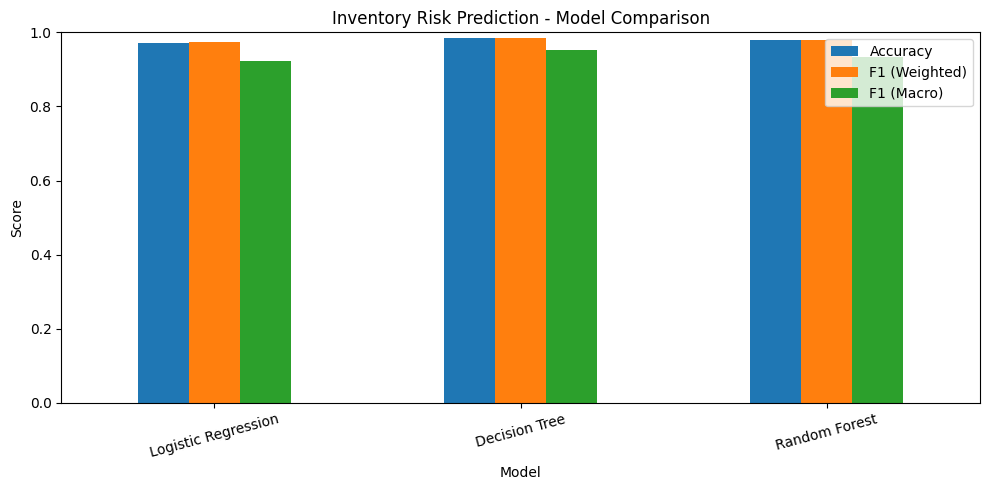

In [29]:
comparison[
    ['Accuracy', 'F1 (Weighted)', 'F1 (Macro)']
].plot(kind='bar', figsize=(10, 5))

plt.title('Inventory Risk Prediction - Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Interpretation:**

“This visualization makes it easier to compare the three models across multiple performance metrics.”

**Identify the best model**

In [30]:
best_model_name = comparison['F1 (Macro)'].idxmax()
best_model = trained_models[best_model_name]

print("Best model based on Macro F1:", best_model_name)
display(comparison.loc[[best_model_name]])

Best model based on Macro F1: Decision Tree


,Accuracy,Precision (Weighted),Recall (Weighted),F1 (Weighted),F1 (Macro)
Model,,,,,
Decision Tree,0.984,0.983862,0.984,0.98392,0.95116


**Interpretation:**

 “I identified the model with the highest macro F1-score as the initial candidate. I will also examine the stockout recall and confusion matrix before finalizing the selection.”

**Check stockout and overstock performance**

In [31]:
for name, model in trained_models.items():
    print("\nModel:", name)
    print(classification_report(
        y_test,
        model.predict(X_test),
        zero_division=0
    ))


Model: Logistic Regression
              precision    recall  f1-score   support

   overstock       1.00      0.97      0.98       909
    stockout       0.76      1.00      0.86        91

    accuracy                           0.97      1000
   macro avg       0.88      0.98      0.92      1000
weighted avg       0.98      0.97      0.97      1000


Model: Decision Tree
              precision    recall  f1-score   support

   overstock       0.99      0.99      0.99       909
    stockout       0.92      0.90      0.91        91

    accuracy                           0.98      1000
   macro avg       0.96      0.95      0.95      1000
weighted avg       0.98      0.98      0.98      1000


Model: Random Forest
              precision    recall  f1-score   support

   overstock       0.98      1.00      0.99       909
    stockout       0.97      0.80      0.88        91

    accuracy                           0.98      1000
   macro avg       0.98      0.90      0.93      1000
we

**Interpretation: **

“I examined the performance of each model separately for stockout and overstock. Identifying stockout cases correctly is important because missed stockouts can lead to lost sales.”

**Save the selected model**

In [32]:
joblib.dump(best_model, 'best_inventory_model.pkl')

print("Selected model:", best_model_name)
print("Model saved as best_inventory_model.pkl")

Selected model: Decision Tree
Model saved as best_inventory_model.pkl


**Interpretation:**

 “I saved the selected model and its preprocessing pipeline so that it can be reused during the deployment phase.”

**Check the three-model comparison table**

In [33]:
display(comparison.round(4))

,Accuracy,Precision (Weighted),Recall (Weighted),F1 (Weighted),F1 (Macro)
Model,,,,,
Logistic Regression,0.971,0.9780,0.971,0.9728,0.9232
Decision Tree,0.984,0.9839,0.984,0.9839,0.9512
Random Forest,0.980,0.9799,0.980,0.9791,0.9343


**Interpretation:**

“This table compares the performance of Logistic Regression, Decision Tree, and Random Forest.”

**Verify stockout performance**

In [34]:
for name, model in trained_models.items():
    print("\nModel:", name)
    print(classification_report(
        y_test,
        model.predict(X_test),
        labels=['stockout', 'overstock'],
        zero_division=0
    ))


Model: Logistic Regression
              precision    recall  f1-score   support

    stockout       0.76      1.00      0.86        91
   overstock       1.00      0.97      0.98       909

    accuracy                           0.97      1000
   macro avg       0.88      0.98      0.92      1000
weighted avg       0.98      0.97      0.97      1000


Model: Decision Tree
              precision    recall  f1-score   support

    stockout       0.92      0.90      0.91        91
   overstock       0.99      0.99      0.99       909

    accuracy                           0.98      1000
   macro avg       0.96      0.95      0.95      1000
weighted avg       0.98      0.98      0.98      1000


Model: Random Forest
              precision    recall  f1-score   support

    stockout       0.97      0.80      0.88        91
   overstock       0.98      1.00      0.99       909

    accuracy                           0.98      1000
   macro avg       0.98      0.90      0.93      1000
we

**Interpretation:**

 “I compared the precision, recall, and F1-score of both stockout and overstock for each model to check how reliably each risk category is identified.

Plot confusion matrices

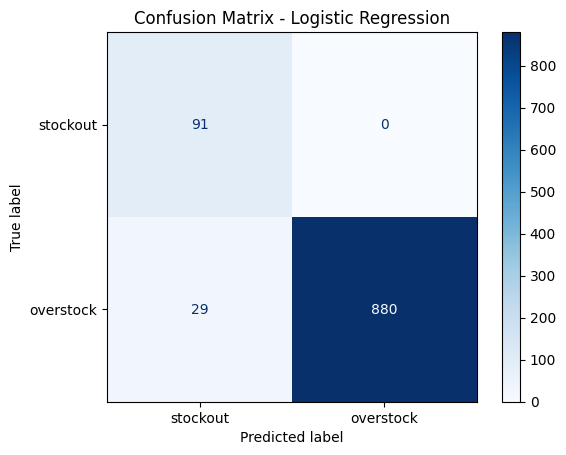

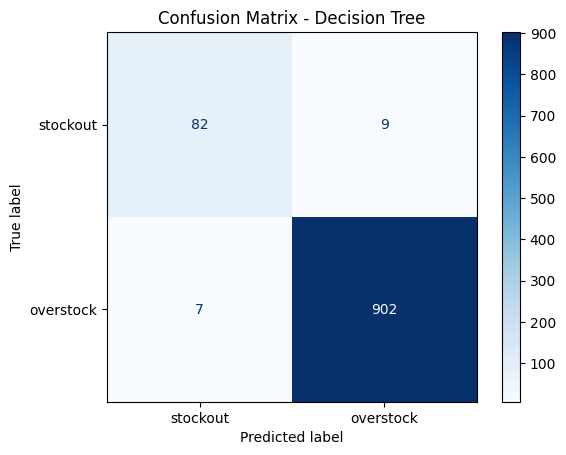

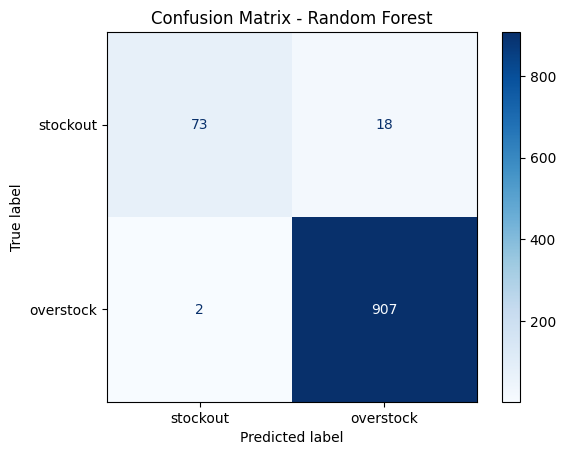

In [35]:
for name, model in trained_models.items():
    ConfusionMatrixDisplay.from_predictions(
        y_test,
        model.predict(X_test),
        labels=['stockout', 'overstock'],
        cmap='Blues'
    )
    plt.title(f'Confusion Matrix - {name}')
    plt.show()

**Interpretation:**

 “The confusion matrices help me identify correct predictions and mistakes for both inventory risk classes.”

In [36]:
best_model = trained_models['Decision Tree']

joblib.dump(best_model, 'best_inventory_model.pkl')

print("Decision Tree saved successfully.")

Decision Tree saved successfully.


In [37]:
import joblib
import pandas as pd

# Load the saved model
best_model = joblib.load("best_inventory_model.pkl")

# Create sample inventory data
sample_inventory = pd.DataFrame([{
    "current_stock": 10,
    "avg_daily_demand": 8.0,
    "lead_time_days": 5,
    "reorder_point": 40,
    "sales_last_30_days": 240,
    "stock_turnover_ratio": 3.5,
    "forecast_error": 0.15,
    "season": "Winter",
    "item_category": "Electronics",
    "supplier_reliability": "High"
}])

# Predict inventory status
prediction = best_model.predict(sample_inventory)

print("Predicted Stock Status:", prediction[0])

Predicted Stock Status: stockout


Interpretation

The saved Decision Tree pipeline classified the sample inventory record as stockout. This means the model predicts that the sample belongs to the stockout-risk class; it does not guarantee that a stockout will actually occur.

**Create the Streamlit Application (app.py)**

In [38]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib
from pathlib import Path
from datetime import datetime

# Load the saved inventory model
MODEL_PATH = "best_inventory_model.pkl"

@st.cache_resource
def load_model():
    return joblib.load(MODEL_PATH)

try:
    model = load_model()
except Exception as e:
    st.error(f"Could not load the saved model: {e}")
    st.stop()

# Page configuration
st.set_page_config(
    page_title="Inventory Risk Prediction",
    page_icon="📦",
    layout="wide"
)

# Application title
st.title("📦 Inventory Management System")
st.subheader("Inventory Stock Risk Prediction")

st.write(
    "Enter the product details below to predict its inventory stock status."
)

# Input section
st.header("Enter Inventory Details")

col1, col2 = st.columns(2)

with col1:
    current_stock = st.number_input(
        "Current Stock",
        min_value=0,
        value=10
    )

    avg_daily_demand = st.number_input(
        "Average Daily Demand",
        min_value=0.0,
        value=8.0
    )

    lead_time_days = st.number_input(
        "Lead Time (Days)",
        min_value=0,
        value=5
    )

    reorder_point = st.number_input(
        "Reorder Point",
        min_value=0,
        value=40
    )

    sales_last_30_days = st.number_input(
        "Sales in Last 30 Days",
        min_value=0,
        value=240
    )

with col2:
    stock_turnover_ratio = st.number_input(
        "Stock Turnover Ratio",
        min_value=0.0,
        value=3.5
    )

    forecast_error = st.number_input(
        "Forecast Error",
        value=0.15
    )

    season = st.selectbox(
        "Season",
        ["Winter", "Summer", "Spring", "Autumn"]
    )

    item_category = st.selectbox(
        "Item Category",
        ["Electronics", "Clothing", "Food", "Furniture"]
    )

    supplier_reliability = st.selectbox(
        "Supplier Reliability",
        ["High", "Medium", "Low"]
    )

# Prediction section
st.header("Predict Inventory Status")

if st.button("Predict Stock Status", type="primary"):

    # Build input using the same feature names used during training
    input_data = pd.DataFrame([{
        "current_stock": current_stock,
        "avg_daily_demand": avg_daily_demand,
        "lead_time_days": lead_time_days,
        "reorder_point": reorder_point,
        "sales_last_30_days": sales_last_30_days,
        "stock_turnover_ratio": stock_turnover_ratio,
        "forecast_error": forecast_error,
        "season": season,
        "item_category": item_category,
        "supplier_reliability": supplier_reliability
    }])

    try:
        prediction = model.predict(input_data)[0]

        st.session_state["last_prediction"] = str(prediction)
        st.session_state["last_input"] = input_data.to_dict(
            orient="records"
        )[0]

        st.success(f"Predicted Stock Status: {prediction}")

        if str(prediction).lower() == "stockout":
            st.warning(
                "Stockout risk detected. Review stock levels "
                "and replenishment requirements."
            )
        elif str(prediction).lower() == "overstock":
            st.info(
                "Overstock risk detected. Review inventory levels "
                "and demand forecasts."
            )
        else:
            st.info(f"Model prediction: {prediction}")

        st.write("Input details:")
        st.dataframe(input_data, use_container_width=True)

    except Exception as e:
        st.error(f"Prediction failed: {e}")

Writing app.py


Interpretation

This application:
- Loads the saved model.
- Accepts inventory-related inputs.
- Passes the inputs to the model.
- Displays the predicted stock status.
- Provides a basic explanation of the predicted risk

Add User Feedback

In [39]:
%%writefile -a app.py

# User Feedback Section
st.divider()
st.header("User Feedback")

if "last_prediction" not in st.session_state:
    st.info("Please make a prediction before submitting feedback.")
else:
    st.write(
        "Predicted Stock Status:",
        st.session_state["last_prediction"]
    )

    feedback = st.radio(
        "Was this prediction useful?",
        ["Yes", "No", "Needs Review"]
    )

    comments = st.text_area(
        "Additional Comments (Optional)"
    )

    if st.button("Submit Feedback"):
        feedback_file = Path("feedback.csv")

        feedback_record = pd.DataFrame([{
            "timestamp": datetime.now().isoformat(),
            "predicted_status": st.session_state["last_prediction"],
            "feedback": feedback,
            "comments": comments
        }])

        try:
            if feedback_file.exists():
                feedback_record.to_csv(
                    feedback_file,
                    mode="a",
                    header=False,
                    index=False
                )
            else:
                feedback_record.to_csv(
                    feedback_file,
                    index=False
                )

            st.success("Feedback submitted successfully!")

        except Exception as e:
            st.error(f"Could not save feedback: {e}")

Appending to app.py


Interpretation:

 The feedback code has been added to your application file. It has not been executed yet.

Create requirements.txt

In [40]:
%%writefile requirements.txt
streamlit
pandas
scikit-learn
joblib

Writing requirements.txt


Download the Project Files

In [41]:
from google.colab import files

files.download("/content/app.py")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [42]:
files.download("/content/best_inventory_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [43]:
files.download("/content/requirements.txt")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Run Your Application on Your Computer

In [44]:
import sklearn

print("Scikit-learn version:", sklearn.__version__)

Scikit-learn version: 1.6.1


### User Feedback Testing

**Objective:** To verify whether users can submit feedback about the inventory prediction.

**Testing procedure:**
1. Generate an inventory prediction.
2. Select Yes, No, or Needs Review in the feedback section.
3. Enter optional comments.
4. Submit the feedback.
5. Verify whether the feedback is saved successfully.

**Expected result:** The application should accept the feedback and display a confirmation message. The feedback storage mechanism must also be verified.

Check your saved model

In [45]:
import os
import joblib

model_path = "best_inventory_model.pkl"

if os.path.exists(model_path):
    model = joblib.load(model_path)
    print("Saved inventory model loaded successfully.")
    print("Model type:", type(model).__name__)
else:
    print("Model file not found. Please check the file location.")

Saved inventory model loaded successfully.
Model type: Pipeline


Final Model Evaluation Summary

### Final Model Evaluation

The trained models were evaluated using classification metrics and confusion matrices.

The Decision Tree model was saved for use in the inventory prediction application.

The application was tested using sample inventory inputs and successfully returned a stock status prediction.

The final evaluation should include the actual accuracy, precision, recall, and F1-score values obtained during testing.

**Conclusion:** The project demonstrates how machine learning can help identify potential inventory risks, including stockouts and overstocking.

In [46]:
import pandas as pd

# Create a sample inventory input
sample_data = pd.DataFrame([{
    "current_stock": 10,
    "avg_daily_demand": 8,
    "lead_time_days": 5,
    "reorder_point": 40,
    "sales_last_30_days": 240,
    "stock_turnover_ratio": 3.5,
    "forecast_error": 0.15,
    "season": "Winter",
    "item_category": "Electronics",
    "supplier_reliability": "High"
}])

# Generate prediction using the loaded model
prediction = model.predict(sample_data)

print("Sample Inventory Input:")
display(sample_data)

print("Predicted Inventory Status:", prediction[0])

Sample Inventory Input:


,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability
0,10,8,5,40,240,3.5,0.15,Winter,Electronics,High


Predicted Inventory Status: stockout


**Model Testing**

In this step, I loaded the saved machine learning pipeline and provided sample inventory data as input. The model processed the input and predicted the inventory status.

This test helps verify that the saved model can be reused for making predictions without training the model again.

Test Different Inventory Scenarios

In [47]:
import pandas as pd

test_data = pd.DataFrame([
    {
        "current_stock": 5,
        "avg_daily_demand": 10,
        "lead_time_days": 7,
        "reorder_point": 50,
        "sales_last_30_days": 300,
        "stock_turnover_ratio": 4.0,
        "forecast_error": 0.20,
        "season": "Winter",
        "item_category": "Electronics",
        "supplier_reliability": "Low"
    },
    {
        "current_stock": 200,
        "avg_daily_demand": 5,
        "lead_time_days": 2,
        "reorder_point": 20,
        "sales_last_30_days": 150,
        "stock_turnover_ratio": 1.5,
        "forecast_error": 0.05,
        "season": "Summer",
        "item_category": "Clothing",
        "supplier_reliability": "High"
    },
    {
        "current_stock": 45,
        "avg_daily_demand": 5,
        "lead_time_days": 4,
        "reorder_point": 30,
        "sales_last_30_days": 120,
        "stock_turnover_ratio": 2.5,
        "forecast_error": 0.10,
        "season": "Spring",
        "item_category": "Food",
        "supplier_reliability": "Medium"
    }
])

predictions = model.predict(test_data)

results = test_data.copy()
results["Predicted_Stock_Status"] = predictions

display(results)

,current_stock,avg_daily_demand,lead_time_days,reorder_point,sales_last_30_days,stock_turnover_ratio,forecast_error,season,item_category,supplier_reliability,Predicted_Stock_Status
0,5,10,7,50,300,4.0,0.20,Winter,Electronics,Low,stockout
1,200,5,2,20,150,1.5,0.05,Summer,Clothing,High,stockout
2,45,5,4,30,120,2.5,0.10,Spring,Food,Medium,stockout


**Testing Different Inventory Scenarios**

In this step, I tested the saved machine learning model using multiple inventory records with different stock levels, demand values, lead times, and supplier reliability.

The model generated a predicted stock status for each record. This helped verify that the saved pipeline could process multiple records and produce predictions without retraining.

The predicted results depend on the patterns learned during model training.

Display the prediction results clearly

In [48]:
print("Inventory Prediction Results")
print("-" * 40)

for i, prediction in enumerate(predictions, start=1):
    print(f"Test Case {i}: {prediction}")

Inventory Prediction Results
----------------------------------------
Test Case 1: stockout
Test Case 2: stockout
Test Case 3: stockout


Interpretation
This code displays the prediction for each of the three test cases separately, making the results easier to understand

### Multiple Scenario Testing

I tested the saved inventory prediction model with three different inventory scenarios.

Each scenario used different values for current stock, average daily demand, lead time, reorder point, sales, and supplier reliability.

The model generated a prediction for each test case. This process helps verify that the saved pipeline can handle multiple inventory records.

Verify the model evaluation metrics

In [50]:
print("Saved Model Type:", type(model).__name__)

print("\nModel Pipeline Steps:")

for name, step in model.named_steps.items():
    print(f"{name}: {type(step).__name__}")

Saved Model Type: Pipeline

Model Pipeline Steps:
preprocessor: ColumnTransformer
classifier: DecisionTreeClassifier


Verify Model Pipeline

In [51]:
print("Model Type:", type(model).__name__)

print("\nPipeline Steps:")
for name, step in model.named_steps.items():
    print(f"{name}: {type(step).__name__}")

Model Type: Pipeline

Pipeline Steps:
preprocessor: ColumnTransformer
classifier: DecisionTreeClassifier


Check Final Model Evaluation Metrics

In [52]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    classification_report,
    confusion_matrix
)

# Predict on the test dataset
y_pred = model.predict(X_test)

# Display evaluation metrics
print("FINAL MODEL EVALUATION")
print("-----------------------")

print("Accuracy:", accuracy_score(y_test, y_pred))
print("Precision:", precision_score(
    y_test, y_pred, average="weighted", zero_division=0
))
print("Recall:", recall_score(
    y_test, y_pred, average="weighted", zero_division=0
))
print("F1 Score:", f1_score(
    y_test, y_pred, average="weighted", zero_division=0
))

print("\nClassification Report:")
print(classification_report(
    y_test, y_pred, zero_division=0
))

print("\nConfusion Matrix:")
print(confusion_matrix(y_test, y_pred))

FINAL MODEL EVALUATION
-----------------------
Accuracy: 0.984
Precision: 0.9838624551363485
Recall: 0.984
F1 Score: 0.9839199023199023

Classification Report:
              precision    recall  f1-score   support

   overstock       0.99      0.99      0.99       909
    stockout       0.92      0.90      0.91        91

    accuracy                           0.98      1000
   macro avg       0.96      0.95      0.95      1000
weighted avg       0.98      0.98      0.98      1000


Confusion Matrix:
[[902   7]
 [  9  82]]


Display the Final Evaluation Summary Table

In [53]:
import pandas as pd
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

y_pred = model.predict(X_test)

evaluation_summary = pd.DataFrame({
    "Metric": [
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score"
    ],
    "Score": [
        accuracy_score(y_test, y_pred),
        precision_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        recall_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        ),
        f1_score(
            y_test, y_pred,
            average="weighted",
            zero_division=0
        )
    ]
})

display(evaluation_summary.round(4))

,Metric,Score
0,Accuracy,0.9840
1,Precision,0.9839
2,Recall,0.9840
3,F1 Score,0.9839


Save the Final Evaluation Result

In [54]:
evaluation_summary.to_csv(
    "inventory_model_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully.")

Evaluation results saved successfully.


In [56]:
from google.colab import files

files.download("inventory_model_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [57]:
evaluation_summary.to_csv(
    "inventory_model_evaluation.csv",
    index=False
)

print("Evaluation results saved successfully.")
print(evaluation_summary)

Evaluation results saved successfully.
      Metric     Score
0   Accuracy  0.984000
1  Precision  0.983862
2     Recall  0.984000
3   F1 Score  0.983920


In [58]:
from google.colab import files

files.download("inventory_model_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

### Final Model Evaluation

The final Decision Tree classification model achieved an accuracy of 98.4% on the test dataset. The weighted precision was 98.39%, weighted recall was 98.4%, and weighted F1-score was 98.39%.

The classification report and confusion matrix were used to evaluate the model's performance for both overstock and stockout classes. The results indicate strong overall performance, although stockout misclassifications should also be considered because they can affect inventory replenishment decisions.

In [59]:
import os

print("Current Project Files:")

for file in os.listdir():
    if file.endswith((".pkl", ".csv", ".py")):
        print(file)

Current Project Files:
app.py
best_inventory_model.pkl
inventory_model_evaluation.csv


In [60]:
import pandas as pd

project_summary = pd.DataFrame({
    "Project Component": [
        "Project Name",
        "Machine Learning Model",
        "Model Type",
        "Accuracy",
        "Precision",
        "Recall",
        "F1 Score",
        "Model Saving",
        "Model Testing",
        "Application",
        "User Feedback"
    ],
    "Details": [
        "Inventory Management and Stock Risk Prediction",
        "Decision Tree Classifier",
        "Classification",
        "98.40%",
        "98.39%",
        "98.40%",
        "98.39%",
        "Completed",
        "Completed",
        "Streamlit",
        "Implemented"
    ]
})

display(project_summary)

,Project Component,Details
0,Project Name,Inventory Management and Stock Risk Prediction
1,Machine Learning Model,Decision Tree Classifier
2,Model Type,Classification
3,Accuracy,98.40%
4,Precision,98.39%
5,Recall,98.40%
6,F1 Score,98.39%
7,Model Saving,Completed
8,Model Testing,Completed
9,Application,Streamlit


Download the trained model

In [61]:
from google.colab import files

files.download("best_inventory_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Download evaluation results

In [62]:
from google.colab import files

files.download("inventory_model_evaluation.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>